INFO:root:building '_cython_magic_08a1035d54a7c4488c26f25634d20bd3' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_08a1035d54a7c4488c26f25634d20bd3.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_08a1035d54a7c4488c26f25634d20bd3.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_08a1035d54a7c4488c26f25634d20bd3.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 16. s
2.69 s (16%) simulated in 10s, estimated 49s remaining.
Switched to HSP phase.
[4000 ms]  rates (mean): 168.3 Hz  
[4000 ms]  rates (mean): 15.5 Hz  
[4100 ms]  rates (mean): 152.0 Hz  
[4100 ms]  rates (mean): 14.2 Hz  
[4200 ms]  rates (mean): 135.0 Hz  
[4200 ms]  rates (mean): 12.5 Hz  
[4300 ms]  rates (mean): 118.3 Hz  
[4300 ms]  rates (mean): 11.1 Hz  
[4400 ms]  rates (mean): 101.5 Hz  
[4400 ms]  rates (mean): 9.6 Hz  
4.4001 s (27%) simulated in 20s, estimated 54s remaining.
[4500 ms]  rates (mean): 84.8 Hz  
[4500 ms]  rates (mean): 7.9 Hz  
[4600 ms]  rates (mean): 68.1 Hz  
[4600 ms]  rates (mean): 6.3 Hz  
[4700 ms]  rates (mean): 51.4 Hz  
[4700 ms]  rates (mean): 5.0 Hz  
[4800 ms]  rates (mean): 34.8 Hz  
[4800 ms]  rates (mean): 3.7 Hz  
[4900 ms]  rates (mean): 18.1 Hz  
[4900 ms]  rates (mean): 2.4 Hz  
[5000 ms]  rates (mean): 1.3 Hz  
[5000 ms]  rates (mean): 1.1 Hz  
[5100 ms]  rates (mean): 0.7 Hz  
[5100 ms

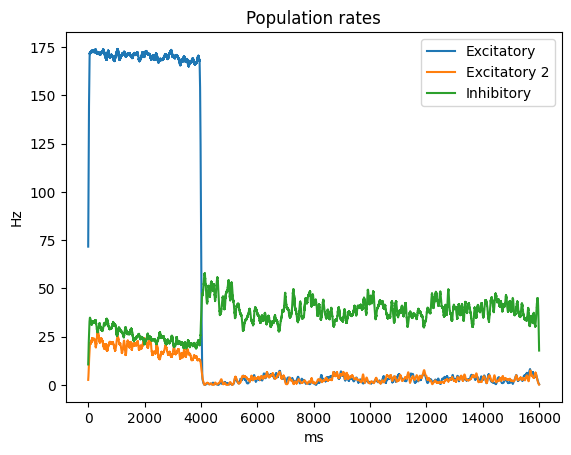

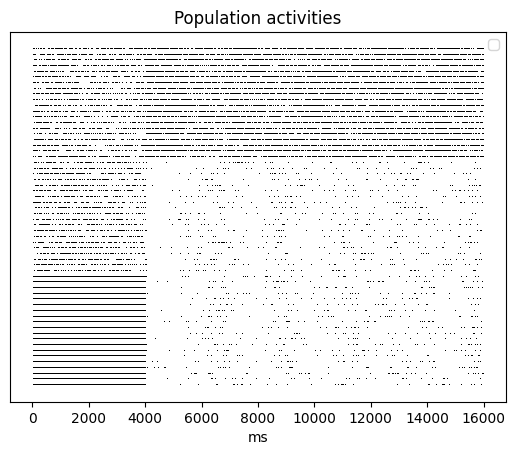

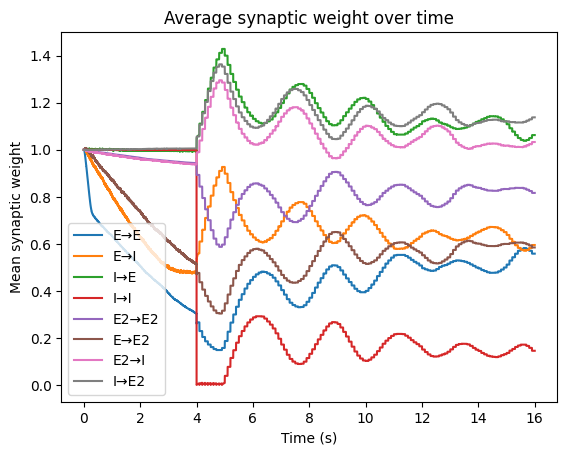

WARNING    /tmp/ipykernel_873/838167443.py:452: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
 [py.warnings]
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)

WARNING    /tmp/ipykernel_873/838167443.py:453: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
 [py.warnings]
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)

WARNING    /tmp/ipykernel_873/838167443.py:454: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argume

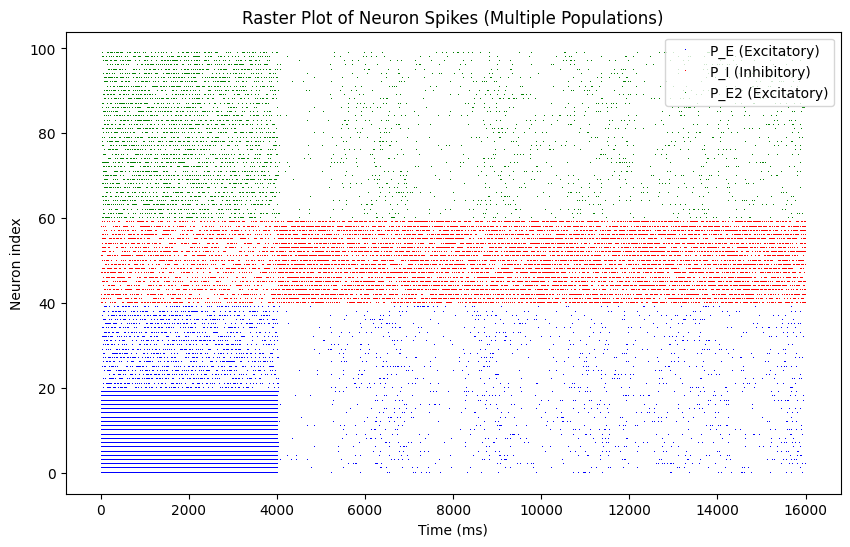

WARNING    /tmp/ipykernel_873/838167443.py:469: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(image_path)
 [py.warnings]
  image = imageio.imread(image_path)



GIF saved as weight_connections.gif


In [20]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os


start_scope()

#gif 
save_interval = 0.1*second  
frames = []
def plot_weights_for_gif(t):
    # Build a full weight matrix from Synapses (N_E x N_E)
    W = np.zeros((N_E, N_E))
    for i, j, w_ij in zip(C_E_E.i[:], C_E_E.j[:], C_E_E.w[:]):
        W[i, j] = w_ij
    
    plt.figure(figsize=(6, 6))
    plt.imshow(W, cmap='hot', interpolation='nearest')
    plt.title(f'Synaptic Weights at t = {t/ms:.0f} ms')
    plt.colorbar(label='Weight')
    plt.xlabel('Post-synaptic neuron')
    plt.ylabel('Pre-synaptic neuron')

    frame = plt.gcf()
    frames.append(frame)
    plt.close()

# Phase durations
learning_duration = 4 * second
hsp_duration = 12 * second

# Control flags
run_phase = 'learning'

pattern_neurons = np.arange(20)  
pattern_rate = 50*Hz  

# populations
N = 100
N_E = int(N * 0.4)  # pyramidal neurons
N_I = int(N * 0.2)  # interneurons
target_rate = 3*Hz
alpha = 0.05 #0.1
window = 1*second
plasticity_dt = 100*ms
max_gate = 3

# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0. * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800

# synapses
C_E = N_E
C_I = N_I

# AMPA
g_AMPA_ext_E = 2.08 * nS
g_AMPA_rec_E = 0.104 * nS 
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS 
tau_AMPA = 2. * ms


# GABAa
g_GABA_E = 0.8*nS #1.25 * nS 
g_GABA_I = 0.8*nS #0.973 * nS 
tau_GABA = 10. * ms


# modeling
eqs_E = '''
dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

eqs_I = '''
dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E.v = V_L
P_E2 = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E2.v = V_L
P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
P_I.v = V_L


# eqs_pre_glut = '''
# s_AMPA += w
# '''

# eqs_pre_gaba = '''
# s_GABA += w
# '''
#STDP
stdp_eqs = '''
w : 1
dpre/dt = -pre/ taupre : 1 (event-driven)
dpost/dt = -post/ taupost : 1 (event-driven)
taupre : second (constant)
taupost : second (constant)
'''

tau_pre = 20*ms
tau_post = 20*ms
Apre = 0.01
Apost = -0.012
w_max = 3.0
on_pre_stdp = '''
s_AMPA += w
pre += 1.
w = clip(w + Apost * post, 0, w_max)
'''

on_post_stdp = '''
post += 1.
w = clip(w + Apre * pre, 0, w_max)
'''
#iSTDP
Apre_i = -0.005   
Apost_i = 0.005
w_max_i = 5.0
iSTDP_eqs = '''
w : 1
dpre/dt = -pre / taupre : 1 (event-driven)
dpost/dt = -post / taupost : 1 (event-driven)
taupre : second (constant)
taupost : second (constant)
'''

on_pre_iSTDP = '''
s_GABA += w
pre += 1.
w = clip(w + Apost_i * post, 0, w_max_i)
'''

on_post_iSTDP = '''
post += 1.
w = clip(w + Apre_i * pre, 0, w_max_i)
'''


#E1
# E to E
C_E_E = Synapses(P_E, P_E,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_E.connect('i != j')
C_E_E.w[:] = 1
C_E_E.taupre = 20*ms
C_E_E.taupost = 20*ms

# E to I
C_E_I = Synapses(P_E, P_I,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_I.connect()
C_E_I.w[:] = 1
C_E_I.taupre = 20*ms
C_E_I.taupost = 20*ms

# I to I
C_I_I = Synapses(P_I, P_I,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_I.connect('i != j')
C_I_I.w[:] = 1
C_I_I.taupre = 20*ms
C_I_I.taupost = 20*ms

# I to E
C_I_E = Synapses(P_I, P_E,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_E.connect()
C_I_E.w[:] = 1
C_I_E.taupre = 20*ms
C_I_E.taupost = 20*ms

#E2
# E1 to E2
C_E_E2 = Synapses(P_E, P_E2,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_E2.connect('i != j')
C_E_E2.w[:] = 1
C_E_E2.taupre = 20*ms
C_E_E2.taupost = 20*ms

# E2 to E2
C_E2_E2 = Synapses(P_E2, P_E2,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E2_E2.connect('i != j')
C_E2_E2.w[:] = 1
C_E2_E2.taupre = 20*ms
C_E2_E2.taupost = 20*ms


# E2 to I
C_E2_I = Synapses(P_E2, P_I,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E2_I.connect('i != j')
C_E2_I.w[:] = 1
C_E2_I.taupre = 20*ms
C_E2_I.taupost = 20*ms

# I to E2
C_I_E2 = Synapses(P_I, P_E2,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_E2.connect()
C_I_E2.w[:] = 1
C_I_E2.taupre = 20*ms
C_I_E2.taupost = 20*ms

# external noise
C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
C_P_E2 = PoissonInput(P_E2, 's_AMPA_ext', C_ext, rate, '1')
C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')

#pattern
C_select=C_ext/4
total_duration = learning_duration+hsp_duration
dt = 100*ms
stim_array = np.zeros(int(total_duration/dt))
stim_array[:int(learning_duration/dt)] = 1
stimuli = TimedArray(stim_array, dt=dt)
pattern_input = PoissonInput(P_E[pattern_neurons], 's_AMPA_ext', C_select, 50*Hz, 'stimuli(t)')


# monitors

sp_E = SpikeMonitor(P_E)
sp_E2 = SpikeMonitor(P_E2)
sp_I = SpikeMonitor(P_I)

r_E = PopulationRateMonitor(P_E)
r_E2 = PopulationRateMonitor(P_E2)
r_I = PopulationRateMonitor(P_I)

mon_C_E_E = StateMonitor(C_E_E, 'w', record=True)
mon_C_E_I = StateMonitor(C_E_I, 'w', record=True)
mon_C_I_E = StateMonitor(C_I_E, 'w', record=True)
mon_C_I_I = StateMonitor(C_I_I, 'w', record=True)
mon_C_E_E2 = StateMonitor(C_E_E2, 'w', record=True)
mon_C_E2_E2 = StateMonitor(C_E2_E2, 'w', record=True)
mon_C_E2_I = StateMonitor(C_E2_I, 'w', record=True)
mon_C_I_E2 = StateMonitor(C_I_E2, 'w', record=True)

@network_operation(dt=save_interval)
def capture_frames():
    plot_weights_for_gif(defaultclock.t)

freeze_flag=0
@network_operation(dt=100*ms)
def phase_control():
    global run_phase
    if defaultclock.t >= learning_duration and run_phase == 'learning':
        run_phase = 'hsp'
        print("Switched to HSP phase.")
        net.remove(phase_control)


@network_operation(dt=plasticity_dt)
def homeostatic_plasticity():
    if run_phase == 'learning':
        return
    t_now = defaultclock.t
    if t_now < window:
        return
    t0 = t_now - window
    #E
    times = sp_E.t
    idxs  = sp_E.i
    rates = np.zeros(N_E)*Hz
    for post in range(N_E):
        mask = np.logical_and(idxs == post, times >= t0)
        count = np.sum(mask)
        rates[post] = count/window
        delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
        for pre in range(N_E):
            if pre == post:
                continue
            C_E_E.w[pre, post] = clip(C_E_E.w[pre, post]+ alpha * delta, 0, 5)
        for pre in range(N_I):
            C_I_E.w[pre, post] = clip(C_I_E.w[pre, post] - alpha * delta, 0, 5)
        for pre in range(N_I):
            C_E_I.w[post, pre] = clip(C_E_I.w[post, pre] - alpha * delta, 0, 5)
    print(f"[{t_now/ms:.0f} ms]  "
          f"rates (mean): {np.mean(rates):.1f} Hz  ")
    #E2
    times = sp_E2.t
    idxs  = sp_E2.i
    rates = np.zeros(N_E)*Hz
    for post in range(N_E):
        mask = np.logical_and(idxs == post, times >= t0)
        count = np.sum(mask)
        rates[post] = count/window
        delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
        for pre in range(N_E):
            if pre == post:
                continue
            C_E2_E2.w[pre, post] = clip(C_E2_E2.w[pre, post]+ alpha * delta, 0, 5)
            C_E_E2.w[pre,post] = clip(C_E_E2.w[pre, post]+ alpha * delta, 0, 5)
        for pre in range(N_I):
            C_I_E2.w[pre, post] = clip(C_I_E2.w[pre, post] - alpha * delta, 0, 3)
        for pre in range(N_I):
            C_E2_I.w[post, pre] = clip(C_E2_I.w[post, pre] - alpha * delta, 0, 3)
    print(f"[{t_now/ms:.0f} ms]  "
          f"rates (mean): {np.mean(rates):.1f} Hz  ")
 
    times1 = sp_E.t
    idxs1  = sp_E.i
    rates1 = np.zeros(N_E)*Hz
    times2 = sp_E2.t
    idxs2  = sp_E2.i
    rates2 = np.zeros(N_E)*Hz
    for post in range(N_E):  #+ N_E
        mask1 = np.logical_and(idxs1 == post, times1 >= t0)
        mask2 = np.logical_and(idxs2 == post, times2 >= t0)
        count1 = np.sum(mask1)
        count2 = np.sum(mask2)
        rates1[post] = count1 / window
        rates2[post] = count2 / window
    avg_rate_E1 = np.mean(rates1) 
    avg_rate_E2 = np.mean(rates2)
    avg_rate_E= (avg_rate_E1+avg_rate_E2)/2
    C_I_I.w[:] = clip(C_I_I.w[:] - alpha * (avg_rate_E - target_rate) / target_rate, 0, 5)

@network_operation(dt=100*ms)
def freeze_stdp_weights():
    global freeze_flag
    if run_phase == 'hsp' and freeze_flag==0:
        C_E_E.pre.code = 's_AMPA += w'  
        C_E_E.post.code = ''
        C_E_I.pre.code = 's_AMPA += w'
        C_E_I.post.code = ''
        C_E2_E2.pre.code = 's_AMPA += w'
        C_E2_E2.post.code = ''
        C_E_E2.pre.code = 's_AMPA += w'
        C_E_E2.post.code = ''
        C_E2_I.pre.code = 's_AMPA += w'
        C_E2_I.post.code = ''
        C_I_E.pre.code = 's_GABA += w'  
        C_I_E.post.code = ''
        C_I_I.pre.code = 's_GABA += w'  
        C_I_I.post.code = ''
        C_I_E2.pre.code = 's_GABA += w'  
        C_I_E2.post.code = ''
        freeze_flag=1 



net = Network(collect())
net.run(learning_duration+ hsp_duration, report='stdout') # 

# plotting
title('Population rates')
xlabel('ms')
ylabel('Hz')
plot(r_E.t / ms, r_E.smooth_rate(width=25 * ms) / Hz, label='Excitatory')
plot(r_E2.t / ms, r_E2.smooth_rate(width=25 * ms) / Hz, label='Excitatory 2')
plot(r_I.t / ms, r_I.smooth_rate(width=25 * ms) / Hz, label='Inhibitory')
legend()
show()
spike_times = np.concatenate([sp_E.t, sp_I.t])
spike_indices = np.concatenate([sp_E.i, sp_I.i + N_E])

title("Population activities")
xlabel('ms')
yticks([])
plot(spike_times/ms, spike_indices, ',k')
legend()
show()



def plot_mean_weight(state_mon, label):
    mean_weight = np.mean(state_mon.w, axis=0)
    plt.plot(state_mon.t/second, mean_weight, label=label)

plt.figure()
plot_mean_weight(mon_C_E_E, 'E→E')
plot_mean_weight(mon_C_E_I, 'E→I')
plot_mean_weight(mon_C_I_E, 'I→E')
plot_mean_weight(mon_C_I_I, 'I→I')
plot_mean_weight(mon_C_E2_E2, 'E2→E2')
plot_mean_weight(mon_C_E_E2, 'E→E2')
plot_mean_weight(mon_C_E2_I, 'E2→I')
plot_mean_weight(mon_C_I_E2, 'I→E2')
plt.xlabel('Time (s)')
plt.ylabel('Mean synaptic weight')
plt.title('Average synaptic weight over time')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
plt.plot(sp_E2.t / ms, sp_E2.i + N_E+N_I, ',k', label='P_E2 (Excitatory)', color='green', markersize=2)
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Raster Plot of Neuron Spikes (Multiple Populations)')
plt.legend()
plt.show()

def create_gif():
    # Convert saved frames to GIF
    gif_filename = 'weight_connections.gif'
    with imageio.get_writer(gif_filename, mode='I', duration=0.1) as writer:
        for frame in frames:
            # Convert the figure to an image
            image_path = 'temp_frame.png'
            frame.savefig(image_path)
            image = imageio.imread(image_path)
            writer.append_data(image)
            os.remove(image_path)  # Remove the temporary image after adding it to the GIF
    
    print(f"GIF saved as {gif_filename}")
create_gif()



<Axes: xlabel='time (ms)', ylabel='neuron index'>

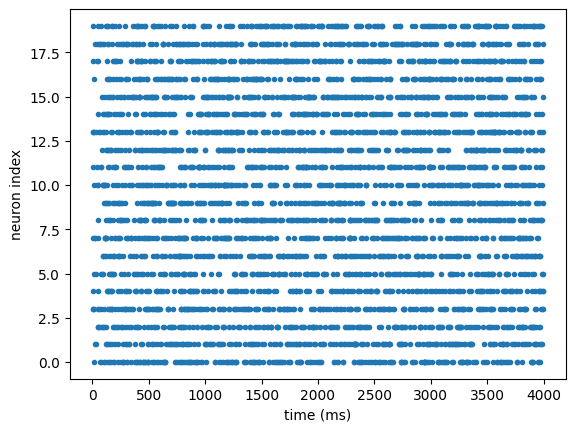

In [9]:
brian_plot(sp_pattern_input)